# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [5]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion_model_name"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy Test: 0.9722
F1 Macro Test: 0.9710

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



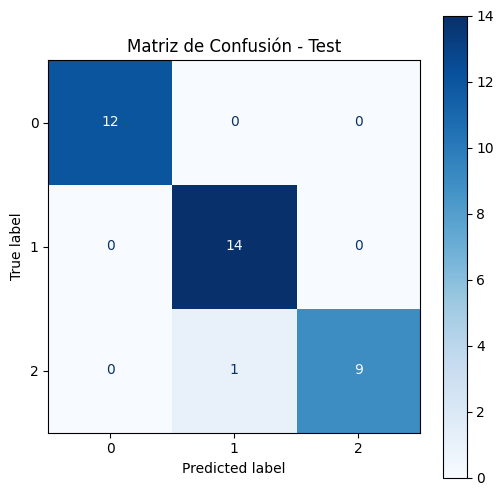

In [7]:
# TODO: calcula predicciones, accuracy y F1 macro
# TODO: muestra classification_report y matriz de confusión
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy Test: {acc:.4f}")
print(f"F1 Macro Test: {f1_macro:.4f}\n")

print("--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
plt.title("Matriz de Confusión - Test")
plt.show()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

El desempeño en el conjunto de prueba es altamente coherente con la validación cruzada, alcanzando una precisión del 97.22% (frente al 97.91% obtenido en la validación cruzada). La única confusión observada ocurre entre la Clase 2 y la Clase 1, donde un ejemplar de la Clase 2 fue clasificado erróneamente como Clase 1. La Clase 0 presentó un desempeño perfecto (100% de precisión y recall). No hay evidencia de sobreajuste, ya que el modelo mantiene una capacidad de generalización sólida sobre datos no vistos.

## 3. Función de inferencia

In [8]:
feature_columns = contract["features"]

feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing_cols = set(feature_columns) - set(records.columns)
    if missing_cols:
        raise ValueError(f"Faltan las siguientes columnas en los datos: {missing_cols}")

    records_ordered = records[feature_columns].copy()

    predictions = model.predict(records_ordered)

    result = records_ordered.copy()
    result["prediction"] = predictions

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(records_ordered)
        for i, class_name in enumerate(model.classes_):
            result[f"probability_class_{class_name}"] = probabilities[:, i]

    return result

## 4. Predicción por lotes

In [9]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

# TODO: llama a predict y guarda batch_predictions.csv
batch_predictions = predict(new_records)

batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)

print("Predicciones por lotes guardadas correctamente.")
print(batch_predictions.head())

Predicciones por lotes guardadas correctamente.
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.10        2.16  2.30               18.0      105.0           2.95   
1    12.51        1.24  2.25               17.5       85.0           2.00   
2    13.87        1.90  2.80               19.4      107.0           2.95   
3    11.56        2.05  3.23               28.5      119.0           3.18   
4    13.67        1.25  1.92               18.0       94.0           2.10   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.32                  0.22             2.38             5.75  1.25   
1        0.58                  0.60             1.25             5.45  0.75   
2        2.97                  0.37             1.76             4.50  1.25   
3        5.08                  0.47             1.87             6.00  0.93   
4        1.79                  0.32             0.73             3.80  1.23   

   od280/od315

## 5. Reporte final

In [10]:
# TODO: guarda test_metrics.json con modelo, accuracy y F1 macro
y_pred = model.predict(X_test)

acc = float(accuracy_score(y_test, y_pred))
f1_macro = float(f1_score(y_test, y_pred, average="macro"))

metrics = {
    "champion_model": training_metadata.get("champion_model_name", training_metadata.get("champion")),
    "accuracy_test": acc,
    "f1_macro_test": f1_macro
}

(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(metrics, indent=4), encoding="utf-8"
)

print("Métricas guardadas en test_metrics.json.")

Métricas guardadas en test_metrics.json.


In [11]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón |LogisticRegression|
| Accuracy CV |0.9791|
| Accuracy test |0.9722|
| F1 macro test |0.9710|
| Clases más confundidas |Clase 2 confundida con Clase 1 (1 caso)|
| Principal limitación |Clase 2 confundida con Clase 1 (1 caso)|

## Checklist

- [ ] Evalué únicamente el modelo campeón.
- [ ] No reajusté hiperparámetros después de observar test.
- [ ] Implementé validación básica del esquema de entrada.
- [ ] Generé predicciones por lotes.
- [ ] Guardé las métricas finales.